# Customer Analysis 

## Objective 

The objective of this notebook is to analyze customer purchasing behavior and identify valuable customer segments using the RFM model.

The RFM model evaluate customers based on: 

- Recency
- Frequency
- Monetary Value 

The insight will support customer retention and marketing strategies.

In [28]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [29]:
# Load Cleaned Dataset
df=pd.read_csv("../data/processed/online_retail_clean.csv")

In [30]:
# Converting InvoiceDate to datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [31]:
sales_df = df[
    (df["Quantity"]>0) &
    (df["Price"]>0)
].copy()

sales_df["Sales"] =(
sales_df["Quantity"] * 
sales_df["Price"]
)

In [32]:
sales_df.info()
sales_df.head()

<class 'pandas.DataFrame'>
Index: 1007914 entries, 0 to 1028000
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1007914 non-null  str           
 1   StockCode    1007914 non-null  str           
 2   Description  1007914 non-null  str           
 3   Quantity     1007914 non-null  int64         
 4   InvoiceDate  1007914 non-null  datetime64[us]
 5   Price        1007914 non-null  float64       
 6   Customer ID  779425 non-null   float64       
 7   Country      1007914 non-null  str           
 8   Sales        1007914 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 126.6 MB


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [33]:
# Set Reference Date

reference_date = sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

print(reference_date)

2011-12-10 12:50:00


In [34]:
# Aggregating sales by customer ID

rfm = sales_df.groupby("Customer ID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "Invoice": "nunique",
    "Sales": "sum"
})

In [35]:
rfm.head()

,InvoiceDate,Invoice,Sales
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40


In [36]:
rfm.columns = [
    "Customer ID",
    "Recency",
    "Frequency",
    "Monetary"
]

ValueError: Length mismatch: Expected axis has 3 elements, new values have 4 elements

In [ ]:
rfm = rfm.reset_index()

In [ ]:
rfm.columns = [
    "Customer ID",
    "Recency",
    "Frequency",
    "Monetary"
]

In [ ]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40


In [ ]:
rfm.info()

<class 'pandas.DataFrame'>
RangeIndex: 5878 entries, 0 to 5877
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Customer ID  5878 non-null   float64
 1   Recency      5878 non-null   int64  
 2   Frequency    5878 non-null   int64  
 3   Monetary     5878 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 183.8 KB


In [ ]:
rfm.describe()

,Customer ID,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000,5878.000000
mean,15315.313542,201.331916,6.289384,2955.904095
std,1715.572666,209.338707,13.009406,14440.852688
min,12346.000000,1.000000,1.000000,2.950000
25%,13833.250000,26.000000,1.000000,342.280000
50%,15314.500000,96.000000,3.000000,867.740000
75%,16797.750000,380.000000,7.000000,2248.305000
max,18287.000000,739.000000,398.000000,580987.040000


### Interpretation

- The dataset contains 5,878 unique customers with complete RFM information.
- The median Recency is 96 days, while 25% of customers have not purchased for more than 380 days, indicating a substantial inactive customer segment.
- Frequency is highly skewed, with 25% of customers making only one purchase, while a few customers purchased hundreds of times.
- These finding support the use of RFM scoring to identify valuable customers and prioritize retention or reactivation strategies.

In [ ]:
# Creating R (Recency) Score

rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=5, 
    labels = [5, 4, 3, 2, 1]
)

In [ ]:
# Checking R Score on the RFM table

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score
0,12346.0,326,12,77556.46,2
1,12347.0,2,8,4921.53,5
2,12348.0,75,5,2019.40,3
3,12349.0,19,4,4428.69,5
4,12350.0,310,1,334.40,2


In [ ]:
# Creating F Score on the RFM table
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"],
    q=5,
    labels=[1, 2, 3, 4, 5]
)

ValueError: Bin edges must be unique: Index([1.0, 1.0, 2.0, 4.0, 8.0, 398.0], dtype='float64', name='Frequency').
You can drop duplicate edges by setting the 'duplicates' kwarg

In [ ]:
# Recreating F score to avoide too many duplicates

rfm["F_Score"]=pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels= [1, 2, 3, 4, 5]
)


In [ ]:
# Checking F Score
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score
0,12346.0,326,12,77556.46,2,5
1,12347.0,2,8,4921.53,5,4
2,12348.0,75,5,2019.40,3,4
3,12349.0,19,4,4428.69,5,3
4,12350.0,310,1,334.40,2,1


## Frequecy Scoring Method

Frequency contains many duplicate values (especially one time purchasers). To ensure stable quantitle-based scoring, ranking was applied before using 'pd.qcut()'.

In [ ]:
# Creating Monetary Score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
)

In [ ]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,326,12,77556.46,2,5,5
1,12347.0,2,8,4921.53,5,4,5
2,12348.0,75,5,2019.40,3,4,4
3,12349.0,19,4,4428.69,5,3,5
4,12350.0,310,1,334.40,2,1,2


In [ ]:
# Coversion of data type (RFM Score to 'str')

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

In [ ]:
# Creating RF Score

rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
) 

In [ ]:
# Checking RF Score
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RF_Score
0,12346.0,326,12,77556.46,2,5,5,255,25
1,12347.0,2,8,4921.53,5,4,5,545,54
2,12348.0,75,5,2019.40,3,4,4,344,34
3,12349.0,19,4,4428.69,5,3,5,535,53
4,12350.0,310,1,334.40,2,1,2,212,21


In [ ]:
#  Customer Segmentation based on RF Score

def segment_customer(rf_score): 

    if rf_score == "55" :
        return "Champion"

    elif rf_score in ["54", "45", "44"]:
        return "Loyal Customer"

    elif rf_score in ["53", "52", "43", "42"]:
        return "Potential Loyalist"

    elif rf_score in ["35", "34", "33"]:
        return "Need Attention"

    elif rf_score in ["25", "24", "23"]:
        return "At Risk"

    elif rf_score in ["15", "14", "13", "12", "11"]:
        return "Lost Customer"

    else:
        return "Others"

In [ ]:
# Creating Segment Columns

rfm["Segment"] = rfm["RF_Score"].apply(segment_customer)

In [ ]:
# Checking Customer Segment Column on RFM Table
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RF_Score,Segment
0,12346.0,326,12,77556.46,2,5,5,255,25,At Risk
1,12347.0,2,8,4921.53,5,4,5,545,54,Loyal Customer
2,12348.0,75,5,2019.40,3,4,4,344,34,Need Attention
3,12349.0,19,4,4428.69,5,3,5,535,53,Potential Loyalist
4,12350.0,310,1,334.40,2,1,2,212,21,Others


In [ ]:
# Counting No of customer by segment

segment_summary = (
    rfm["Segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = ["Segment", "Customer Count"]

segment_summary

,Segment,Customer Count
0,Lost Customer,1175
1,Others,1174
2,Loyal Customer,911
3,Need Attention,782
4,Potential Loyalist,714
5,Champion,571
6,At Risk,551


In [ ]:
# Number and proportion of customer by segment 

segment_summary["Percentage"] = (
    segment_summary["Customer Count"]
    / segment_summary["Customer Count"].sum()
    *100
).round(1)

segment_summary

,Segment,Customer Count,Percentage
0,Lost Customer,1175,20.0
1,Others,1174,20.0
2,Loyal Customer,911,15.5
3,Need Attention,782,13.3
4,Potential Loyalist,714,12.1
5,Champion,571,9.7
6,At Risk,551,9.4


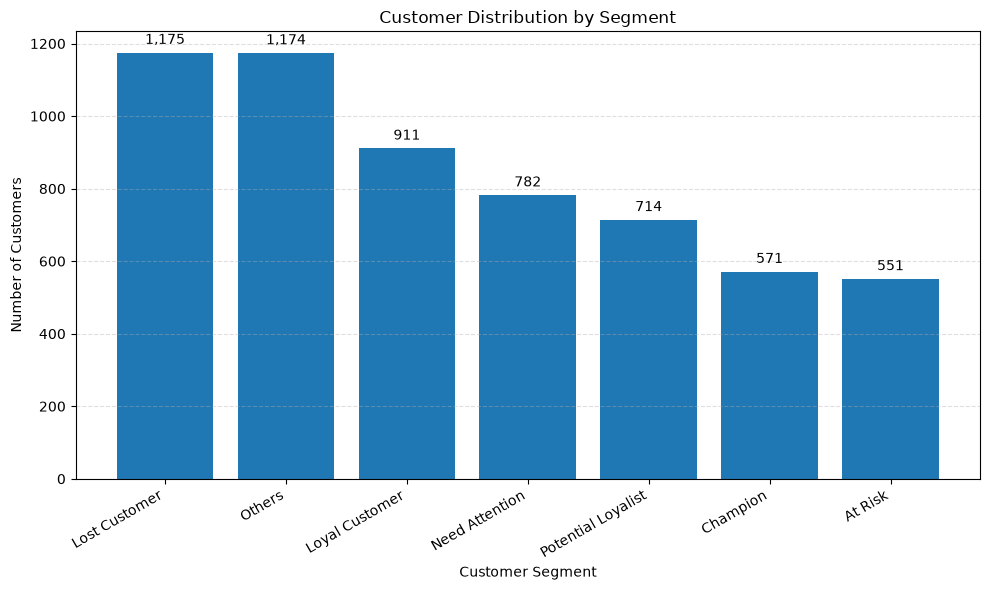

In [ ]:
# Creating Bar Chart to make comparison between segments

plt.figure(figsize=(10,6))

bars= plt.bar(
    segment_summary["Segment"],
    segment_summary["Customer Count"]
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30, ha="right")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar in bars: 
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height +15, 
        f"{int(height):,}",
        ha= "center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
"rfm" in globals()

True

In [ ]:
[x for x in globals() if "rfm" in x.lower()]

['rfm']

In [ ]:
import pandas as pd

# 날짜 형식 확인
sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"]
)

# 분석 기준일: 마지막 거래일 다음 날
snapshot_date = (
    sales_df["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# 고객별 RFM 집계
rfm = (
    sales_df
    .dropna(subset=["Customer ID"])
    .groupby("Customer ID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=("Invoice", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40


In [ ]:
print(rfm.columns.tolist())

['Customer ID', 'Recency', 'Frequency', 'Monetary']


In [ ]:
segment_summary = (
    rfm.groupby("Customer Segment")
       .agg(
           Customers=("Customer Segment", "size"),
           Revenue=("Monetary", "sum")
       )
       .reset_index()
)

segment_summary

KeyError: 'Customer Segment'

In [ ]:
# Revenue by customer segment 

sales_segment = sales_df.merge(
    rfm[["Customer ID", "Segment"]],
    on = "Customer ID",
    how="left"
)

sales_segment.head()


KeyError: "['Segment'] not in index"

In [ ]:
# Total sales revenue by segments

segment_revenue = (
    sales_segment
    .groupby("Segment", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
)

segment_revenue

NameError: name 'sales_segment' is not defined

In [ ]:
# Total sales revenue and proportion by segement 

segment_revenue["Revenue %"] = (
    segment_revenue["Sales"]
    / segment_revenue["Sales"].sum()
    * 100
).round(1)

segment_revenue

NameError: name 'segment_revenue' is not defined

### Business Insight

- Champion customers represent only  **9.7%** of the customer base but generate **48.1%**of total revenue.
- Champion and Loyal customers together contribute approximately **69.2%** of total sales, highlighting the importance of retaining high-value customers.
- Need Attention customers still account for **11.7%** of revenue, suggesting an opportunity for proactive retention campaigns.
- The analysis confirms that customer value is highly concentrated among a relatively small group of customers, consistent with the Pareto Principle.

In [ ]:
# Join two table (Revenue table + Customer Count Table) 

segment_value = segment_revenue.merge(
    segment_summary,
    on="Segment"
)

segment_value

NameError: name 'segment_revenue' is not defined

In [ ]:
# Average Revenue per Customer (Proxy for Customer Lifetime Value)

segment_value["Avg Revenue per Customer"] = (
    segment_value["Sales"]
    /segment_value["Customer Count"]
).round(2)

segment_value

### Business Insight

- Champion customers generated the highest average revenue per customer (£14,648), making them the most valuable customer segment.
- Although Loyal Customers accounted for a larger customer base, their average customer value was significantly lower than that of Champions. 
- Need Attention customers still showed relatively high customer value, indicating strong potential for targeted retention campaigns.
- Lost Customers represented a large proportion of the customer base but generated relatively low average revenue per customer, suggesting that seletive reactivation strategies may be more cost-effective than braod campaigns.

In [ ]:
# Revenue by segment chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    segment_revenue["Segment"],
    segment_revenue["Sales"]
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=30, ha="right")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"£{height / 1_000_000:.1f}M",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

from matplotlib.ticker import FuncFormatter

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x/ 1_000_000:.0f}M")
)

plt.show()


NameError: name 'segment_revenue' is not defined

<Figure size 1000x600 with 0 Axes>

### Interpretation

- Champion customers generated approximately £8.4 million, accounting for the highest revenue among all segments.
- Loyal Customers contributed the second-largest revenue at approximately £3.7million.
- Champion and Loyal Customers together generated about 69% of total revenue.
- Need Attention and At Risk customers also contributed meaningful revenue, indicating opportunities for targeted retention campaigns.

In [ ]:
## Average sales revenue per customers by segment

plt.figure (figsize=(10,6))

bars = plt.bar(
    segment_value["Segment"],
    segment_value["Avg Revenue per Customer"]
)

plt.title("Average Revenue per Customer by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Revenue per Customer (£)")

plt.xticks(rotation=30, ha= "right")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height +100,
        f"£{height:,.0f}",
        ha= "center",
        va= "bottom"
    )
plt.subplots_adjust(
    bottom=0.25,
    top=0.90
)
plt.show()

NameError: name 'segment_value' is not defined

<Figure size 1000x600 with 0 Axes>

### Interpretation
- Champion customers generated the highest average revenue per customer at approximately £14,648.
- Their average value was about 3.6 times higher than that of Loyal Customers.
- Need Attention and At Risk Customers still showed meaningful customer value, supporting targeting retention strategeis.
- Lost Customers and Others had much lower average revenue per customer, suggesting that broad reactivation campaigns may be less cost-effective.


# Customer Analysis Summary

This analysis used the RFM (Recency, Frequency, Monetary) model to segment customers based on purchasing behavior and evaluate customer value.

Key findings include: 

- Champion customers represented only 9.7% of all customers but generated 48.1% of total revenue.
- Champion and Loyal Customers together contributed approximately 69% of total sales. 
- Need Attention and At Risk customers still generated meaningful revenue, indicating opportunities for targeted retention strategies.
- Lost Customers accounted for 20% of the customer base but generated relatively low average revenue per customer.
- The analysis confirmed that customer value is highly concentrated among a relatively small group of customers, supporting the Pareto Principle. 

Overall, the findings demonstrate how customer segmentation can support data-driven business decisions by identifying high-value customers, prioritizing retention efforts, and optimizing marketing investments. This result provide practical insights for improving customer relationship management and driving sustainable business growth.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(    "Hello World"    )

Hello World


In [ ]:
['Customer ID', 'Recency', 'Frequency', 'Monetary']

['Customer ID', 'Recency', 'Frequency', 'Monetary']

In [ ]:
# Recency: 낮을수록 좋은 고객
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: 높을수록 좋은 고객
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: 높을수록 좋은 고객
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

In [ ]:
rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
)

In [ ]:
def assign_customer_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]

    if r == 4 and f == 4:
        return "Champion"

    elif r >= 3 and f >= 3:
        return "Loyal Customer"

    elif r >= 3 and f <= 2:
        return "Potential Loyalist"

    elif r == 2 and f >= 3:
        return "Need Attention"

    elif r == 1 and f >= 3:
        return "At Risk"

    elif r == 1 and f <= 2:
        return "Lost Customer"

    else:
        return "Others"

In [ ]:
rfm["Customer Segment"] = rfm.apply(
    assign_customer_segment,
    axis=1
)

KeyError: 'R_Score'

In [ ]:
print(rfm.columns.tolist())

['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RF_Score', 'Customer Segment']


In [ ]:
rfm["Customer Segment"].value_counts()

Customer Segment
Loyal Customer        1285
Lost Customer         1233
Potential Loyalist     894
Others                 812
Champion               774
Need Attention         654
At Risk                226
Name: count, dtype: int64

In [ ]:
segment_summary = (
    rfm.groupby("Customer Segment")
       .agg(
           Customers=("Customer ID", "nunique"),
           Revenue=("Monetary", "sum"),
           Avg_Revenue_Per_Customer=("Monetary", "mean")
       )
       .reset_index()
)

segment_summary

,Customer Segment,Customers,Revenue,Avg_Revenue_Per_Customer
0,At Risk,226,452355.211,2001.571730
1,Champion,774,9593153.675,12394.255394
2,Lost Customer,1233,588924.692,477.635598
3,Loyal Customer,1285,3736380.924,2907.689435
4,Need Attention,654,1712672.333,2618.765035
5,Others,812,527869.912,650.086099
6,Potential Loyalist,894,763447.521,853.968144


In [ ]:
print(segment_summary.columns.tolist())
display(segment_summary)

['Customer Segment', 'Customers', 'Revenue', 'Avg_Revenue_Per_Customer']


,Customer Segment,Customers,Revenue,Avg_Revenue_Per_Customer
0,At Risk,226,452355.211,2001.571730
1,Champion,774,9593153.675,12394.255394
2,Lost Customer,1233,588924.692,477.635598
3,Loyal Customer,1285,3736380.924,2907.689435
4,Need Attention,654,1712672.333,2618.765035
5,Others,812,527869.912,650.086099
6,Potential Loyalist,894,763447.521,853.968144


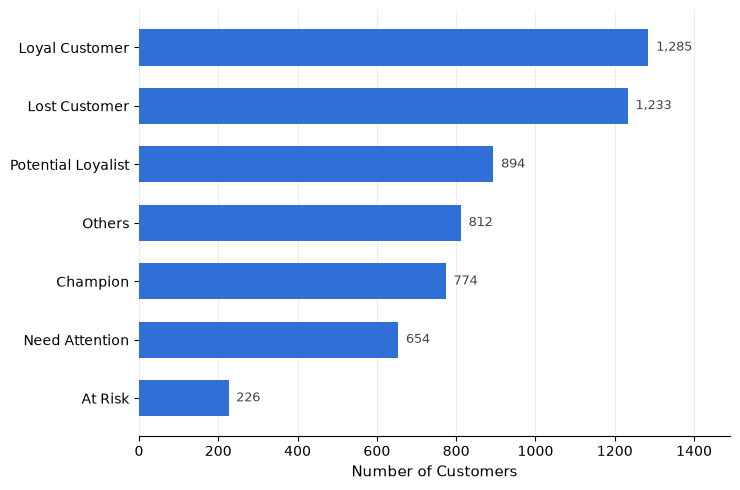

In [ ]:
import matplotlib.pyplot as plt

customer_plot = (
    segment_summary
    .sort_values("Customers", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(7.5, 5))

bars = ax.barh(
    customer_plot["Customer Segment"],
    customer_plot["Customers"],
    color="#2F6FD6",
    height=0.62
)

# 차트 제목 제거 (README의 제목을 사용)

ax.set_xlabel("Number of Customers", fontsize=11)
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.22)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

max_customers = customer_plot["Customers"].max()

for bar in bars:
    value = bar.get_width()

    ax.text(
        value + max_customers * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=9,
        color="#444444"
    )

ax.set_xlim(0, max_customers * 1.16)

plt.tight_layout()

plt.savefig(
    "../images/rfm_customer_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

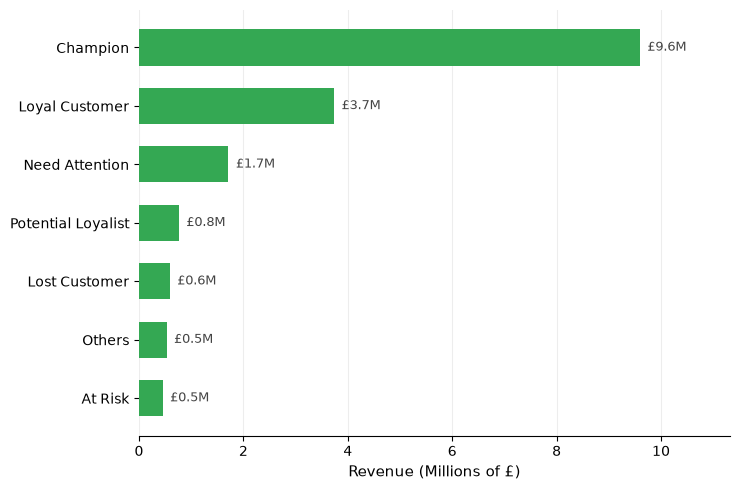

In [ ]:
revenue_plot = (
    segment_summary
    .sort_values("Revenue", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(7.5, 5))

bars = ax.barh(
    revenue_plot["Customer Segment"],
    revenue_plot["Revenue"],
    color="#34A853",
    height=0.62
)

# 차트 제목 제거 (README의 제목을 사용)

ax.set_xlabel("Revenue (Millions of £)", fontsize=11)
ax.set_ylabel("")

ax.grid(
    axis="x",
    alpha=0.22
)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

max_revenue = revenue_plot["Revenue"].max()

# 데이터 레이블
for bar in bars:
    value = bar.get_width()

    ax.text(
        value + max_revenue * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"£{value / 1_000_000:.1f}M",
        va="center",
        fontsize=9,
        color="#444444"
    )

# x축을 백만 파운드 단위로 표시
ticks = ax.get_xticks()

ax.set_xticks(ticks)
ax.set_xticklabels([
    f"{tick / 1_000_000:.0f}"
    for tick in ticks
])

ax.set_xlim(0, max_revenue * 1.18)

plt.tight_layout()

plt.savefig(
    "../images/rfm_revenue_by_segment.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [ ]:
# Identify existing RFM DataFrames

import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if "rfm" in name.lower() or "segment" in name.lower():
            print(f"\nDataFrame: {name}")
            print(f"Shape: {obj.shape}")
            print(f"Columns: {obj.columns.tolist()}")


DataFrame: rfm
Shape: (5878, 3)
Columns: ['InvoiceDate', 'Invoice', 'Sales']


In [ ]:

# Slide 07 - RFM Data Validation

print("=== RFM STRUCTURE ===")
print("Shape:", rfm.shape)
print("Index Name:", rfm.index.name)
print("Index Unique:", rfm.index.is_unique)

print("\n=== RFM SAMPLE ===")
display(rfm.head())

print("\n=== RFM SUMMARY ===")
display(rfm.describe())

print("\n=== MISSING VALUES ===")
print(rfm.isna().sum())


=== RFM STRUCTURE ===
Shape: (5878, 3)
Index Name: Customer ID
Index Unique: True

=== RFM SAMPLE ===


,InvoiceDate,Invoice,Sales
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40



=== RFM SUMMARY ===


,InvoiceDate,Invoice,Sales
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000



=== MISSING VALUES ===
InvoiceDate    0
Invoice        0
Sales          0
dtype: int64


In [ ]:

# Slide 07 - Customer Revenue Pareto Analysis

import pandas as pd

# 1. Sort customers by revenue
customer_pareto = (
    rfm[["Sales"]]
    .sort_values("Sales", ascending=False)
    .reset_index()
)

# 2. Calculate cumulative revenue
customer_pareto["Cumulative Revenue"] = (
    customer_pareto["Sales"].cumsum()
)

customer_pareto["Cumulative Percentage"] = (
    customer_pareto["Cumulative Revenue"]
    / customer_pareto["Sales"].sum() * 100
)

# 3. Identify customers needed to reach 80% revenue
cutoff = customer_pareto[
    customer_pareto["Cumulative Percentage"] >= 80
].index[0]

top_customer_count = cutoff + 1
total_customers = len(customer_pareto)

top_customer_share = (
    top_customer_count / total_customers * 100
)

top_revenue_share = (
    customer_pareto.iloc[:top_customer_count]["Sales"].sum()
    / customer_pareto["Sales"].sum() * 100
)

# 4. Calculate customer revenue
rfm_total_revenue = customer_pareto["Sales"].sum()

print("=== CUSTOMER REVENUE PARETO ===")
print(f"Total Customers: {total_customers:,}")
print(f"Customer Revenue: £{rfm_total_revenue:,.2f}")
print(f"Customers for 80% Revenue: {top_customer_count:,}")
print(f"Customer Share: {top_customer_share:.2f}%")
print(f"Revenue Share: {top_revenue_share:.2f}%")

# 5. Show top customers
print("\n=== TOP 5 CUSTOMERS ===")
display(customer_pareto.head(5))


=== CUSTOMER REVENUE PARETO ===
Total Customers: 5,878
Customer Revenue: £17,374,804.27
Customers for 80% Revenue: 1,354
Customer Share: 23.04%
Revenue Share: 80.01%

=== TOP 5 CUSTOMERS ===


,Customer ID,Sales,Cumulative Revenue,Cumulative Percentage
0,18102.0,580987.04,580987.04,3.343848
1,14646.0,528602.52,1109589.56,6.386199
2,14156.0,313437.62,1423027.18,8.190177
3,14911.0,291420.81,1714447.99,9.867438
4,17450.0,244784.25,1959232.24,11.276284


In [ ]:

# Slide 08 - Find existing RFM segmentation results

import pandas as pd

print("=== SEGMENTATION DATAFRAMES ===")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        cols = [str(c) for c in obj.columns]

        if any(
            "segment" in c.lower()
            or "rfm_score" in c.lower()
            for c in cols
        ):
            print(f"\nDataFrame: {name}")
            print(f"Shape: {obj.shape}")
            print(f"Columns: {cols}")
            display(obj.head(3))

print("\n=== RFM RELATED VARIABLES ===")

for name in list(globals().keys()):
    if (
        "rfm" in name.lower()
        or "segment" in name.lower()
    ) and not name.startswith("_"):
        print(name)


=== SEGMENTATION DATAFRAMES ===

=== RFM RELATED VARIABLES ===
rfm
rfm_total_revenue


In [ ]:
# Find existing RFM-related variables

for name, value in globals().copy().items():
    if name.startswith("_"):
        continue

    if any(
        keyword in name.lower()
        for keyword in [
            "score",
            "segment",
            "champion",
            "loyal",
            "monetary",
            "recency",
            "frequency"
        ]
    ):
        print(f"{name}: {type(value).__name__}")

In [ ]:

# RFM Segmentation Consistency Check

print("=== CURRENT RFM STRUCTURE ===")
print("Shape:", rfm.shape)
print("Columns:", rfm.columns.tolist())
print("Index Name:", rfm.index.name)

if "Customer Segment" in rfm.columns:
    print("\n=== CURRENT SEGMENT COUNTS ===")
    print(rfm["Customer Segment"].value_counts())

if "Customer ID" in rfm.columns:
    print("\n=== UNIQUE CUSTOMERS ===")
    print(rfm["Customer ID"].nunique())

print("\n=== SEGMENT SUMMARY ===")
display(segment_summary)


=== CURRENT RFM STRUCTURE ===
Shape: (5878, 3)
Columns: ['InvoiceDate', 'Invoice', 'Sales']
Index Name: Customer ID

=== SEGMENT SUMMARY ===


NameError: name 'segment_summary' is not defined

In [37]:
print("=== FINAL RFM SEGMENTS ===")

print(
    rfm["Customer Segment"]
    .value_counts()
)

print("\nTotal Customers:", len(rfm))
print("Unique Customers:", rfm.index.nunique())

=== FINAL RFM SEGMENTS ===


KeyError: 'Customer Segment'

In [38]:
print("=== RFM Columns ===")
print(rfm.columns.tolist())

print("\n=== RFM Shape ===")
print(rfm.shape)

=== RFM Columns ===
['InvoiceDate', 'Invoice', 'Sales']

=== RFM Shape ===
(5878, 3)


In [39]:
rfm["Customer Segment"] = rfm["Segment"]

KeyError: 'Segment'

In [40]:
print("=== RFM STATUS ===")
print("Shape:", rfm.shape)
print("Columns:", rfm.columns.tolist())
print("Index:", rfm.index.name)

print("\n=== RFM Preview ===")
display(rfm.head())

=== RFM STATUS ===
Shape: (5878, 3)
Columns: ['InvoiceDate', 'Invoice', 'Sales']
Index: Customer ID

=== RFM Preview ===


,InvoiceDate,Invoice,Sales
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40


In [41]:
# Restore RFM analysis columns
rfm = rfm.rename(columns={
    "InvoiceDate": "Recency",
    "Invoice": "Frequency",
    "Sales": "Monetary"
})

# Validate restored RFM data
print("=== RFM RESTORED ===")
print("Shape:", rfm.shape)
print("Columns:", rfm.columns.tolist())
print("Unique Customers:", rfm.index.nunique())

display(rfm.head())

=== RFM RESTORED ===
Shape: (5878, 3)
Columns: ['Recency', 'Frequency', 'Monetary']
Unique Customers: 5878


,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40


In [42]:
# STEP 2: RFM Scoring (4 Quartiles)

# Recency: Lower is better
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: Higher is better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: Higher is better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Combine R and F scores
rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
)

# Validation
print("=== RFM SCORING VALIDATION ===")
print("Shape:", rfm.shape)

print("\nScore Ranges:")
print(
    rfm[["R_Score", "F_Score", "M_Score"]]
    .agg(["min", "max"])
)

display(rfm.head())

=== RFM SCORING VALIDATION ===
Shape: (5878, 7)

Score Ranges:
     R_Score  F_Score  M_Score
min        1        1        1
max        4        4        4


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RF_Score
Customer ID,,,,,,,
12346.0,326,12,77556.46,2,4,4,24
12347.0,2,8,4921.53,4,4,4,44
12348.0,75,5,2019.40,3,3,3,33
12349.0,19,4,4428.69,4,3,4,43
12350.0,310,1,334.40,2,1,1,21


In [43]:
# STEP 3: Customer Segmentation

def assign_customer_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]

    if r == 4 and f == 4:
        return "Champion"

    elif r >= 3 and f >= 3:
        return "Loyal Customer"

    elif r >= 3 and f <= 2:
        return "Potential Loyalist"

    elif r == 2 and f >= 3:
        return "Need Attention"

    elif r == 1 and f >= 3:
        return "At Risk"

    elif r == 1 and f <= 2:
        return "Lost Customer"

    else:
        return "Others"


# Apply segmentation
rfm["Customer Segment"] = rfm.apply(
    assign_customer_segment,
    axis=1
)

# Validation
print("=== CUSTOMER SEGMENTATION ===")

print(
    rfm["Customer Segment"]
    .value_counts()
)

print("\nTotal Customers:", len(rfm))
print("Assigned Customers:",
      rfm["Customer Segment"].notna().sum())

display(rfm.head())

=== CUSTOMER SEGMENTATION ===
Customer Segment
Loyal Customer        1285
Lost Customer         1233
Potential Loyalist     894
Others                 812
Champion               774
Need Attention         654
At Risk                226
Name: count, dtype: int64

Total Customers: 5878
Assigned Customers: 5878


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RF_Score,Customer Segment
Customer ID,,,,,,,,
12346.0,326,12,77556.46,2,4,4,24,Need Attention
12347.0,2,8,4921.53,4,4,4,44,Champion
12348.0,75,5,2019.40,3,3,3,33,Loyal Customer
12349.0,19,4,4428.69,4,3,4,43,Loyal Customer
12350.0,310,1,334.40,2,1,1,21,Others


In [44]:
# STEP 4: Segment Revenue Analysis

segment_summary = (
    rfm.groupby("Customer Segment")
       .agg(
           Customers=("Monetary", "size"),
           Revenue=("Monetary", "sum"),
           Avg_Revenue_Per_Customer=("Monetary", "mean")
       )
       .reset_index()
)

# Calculate shares
segment_summary["Customer_Share"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum() * 100
)

segment_summary["Revenue_Share"] = (
    segment_summary["Revenue"]
    / segment_summary["Revenue"].sum() * 100
)

# Sort by revenue
segment_summary = segment_summary.sort_values(
    "Revenue", ascending=False
).reset_index(drop=True)

# Validation
print("=== FINAL SEGMENT SUMMARY ===")
print("Total Customers:", segment_summary["Customers"].sum())
print("Total Revenue:", round(segment_summary["Revenue"].sum(), 2))
print("Customer Share:", round(segment_summary["Customer_Share"].sum(), 2))
print("Revenue Share:", round(segment_summary["Revenue_Share"].sum(), 2))

display(segment_summary.round(2))

=== FINAL SEGMENT SUMMARY ===
Total Customers: 5878
Total Revenue: 17374804.27
Customer Share: 100.0
Revenue Share: 100.0


,Customer Segment,Customers,Revenue,Avg_Revenue_Per_Customer,Customer_Share,Revenue_Share
0,Champion,774,9593153.68,12394.26,13.17,55.21
1,Loyal Customer,1285,3736380.92,2907.69,21.86,21.50
2,Need Attention,654,1712672.33,2618.77,11.13,9.86
3,Potential Loyalist,894,763447.52,853.97,15.21,4.39
4,Lost Customer,1233,588924.69,477.64,20.98,3.39
5,Others,812,527869.91,650.09,13.81,3.04
6,At Risk,226,452355.21,2001.57,3.84,2.60
